# Lakehouse tour

A guided look at the lake that `make pipeline demos` produced: layers, quarantine, Iceberg metadata tables, time travel and the gold marts. Every output below was produced by executing this notebook against the running lab.

In [1]:
from lakehouse.spark import session
spark = session('notebook-tour')
spark.sql('SHOW NAMESPACES IN lake').show()

+---------+
|namespace|
+---------+
|   bronze|
|     gold|
|      ops|
|   silver|
+---------+



## 1. Row counts per layer

In [2]:
tables = ['bronze.cdr_raw', 'bronze.sessions_raw', 'silver.cdr', 'silver.sessions', 'silver.quarantine',
          'gold.daily_subscriber_usage', 'gold.cell_hourly_load', 'gold.churn_features',
          'gold.cell_congestion_ranking']
spark.createDataFrame([(t, spark.table(f'lake.{t}').count()) for t in tables], 'table string, rows long').show(truncate=False)

+----------------------------+------+
|table                       |rows  |
+----------------------------+------+
|bronze.cdr_raw              |126296|
|bronze.sessions_raw         |132354|
|silver.cdr                  |123989|
|silver.sessions             |130784|
|silver.quarantine           |877   |
|gold.daily_subscriber_usage |13865 |
|gold.cell_hourly_load       |19377 |
|gold.churn_features         |2000  |
|gold.cell_congestion_ranking|120   |
+----------------------------+------+



## 2. Why records were quarantined

Each failed record keeps the first rule it broke and its raw payload.

In [3]:
spark.sql('''SELECT feed, reason, count(*) AS records, first(payload) AS example
             FROM lake.silver.quarantine GROUP BY feed, reason ORDER BY records DESC''').show(truncate=70)

+--------+-----------------+-------+----------------------------------------------------------------------+
|    feed|           reason|records|                                                               example|
+--------+-----------------+-------+----------------------------------------------------------------------+
|sessions|     unknown_cell|    280|{"session_id":"D000000014714","msisdn":"905900001252","start":"2026...|
|     cdr|     unknown_cell|    276|{"record_id":"R000000007121","calling_msisdn":"905900000682","start...|
|     cdr|   invalid_msisdn|    232|{"record_id":"R000000008078","calling_msisdn":"9059000?","start_tim...|
|     cdr|negative_duration|     89|{"record_id":"R000000000093","calling_msisdn":"905900000007","start...|
+--------+-----------------+-------+----------------------------------------------------------------------+



## 3. Iceberg metadata: snapshots and partition specs of `silver.cdr`

In [4]:
spark.sql('''SELECT committed_at, snapshot_id, operation, summary['added-records'] AS added,
                    summary['total-records'] AS total, summary['total-data-files'] AS data_files
             FROM lake.silver.cdr.snapshots ORDER BY committed_at''').show(truncate=False)
spark.sql('SELECT spec_id, count(*) AS files, sum(record_count) AS records FROM lake.silver.cdr.files GROUP BY 1').show()

+-----------------------+-------------------+---------+------+------+----------+
|committed_at           |snapshot_id        |operation|added |total |data_files|
+-----------------------+-------------------+---------+------+------+----------+
|2026-11-20 23:00:56.038|3533715462069026260|replace  |123989|123989|14        |
|2026-11-20 23:00:56.296|3441612986512279690|replace  |NULL  |123989|14        |
|2026-11-20 23:00:56.48 |3639865065550844752|replace  |NULL  |123989|14        |
+-----------------------+-------------------+---------+------+------+----------+



+-------+-----+-------+
|spec_id|files|records|
+-------+-----+-------+
|      1|   14| 123989|
+-------+-----+-------+



## 4. Time travel

`gold.daily_subscriber_usage` was rebuilt after the correction feed. Its first snapshot is still readable, so the effect of the corrections can be measured exactly.

In [5]:
first = spark.sql('SELECT snapshot_id FROM lake.gold.daily_subscriber_usage.snapshots ORDER BY committed_at LIMIT 1').first()[0]
spark.sql(f'''SELECT 'first build' AS version, count(*) AS subscriber_days, sum(voice_calls) AS calls, sum(charge_try) AS charge
              FROM lake.gold.daily_subscriber_usage VERSION AS OF {first}
              UNION ALL SELECT 'current', count(*), sum(voice_calls), sum(charge_try) FROM lake.gold.daily_subscriber_usage''').show()

+-----------+---------------+-----+---------+
|    version|subscriber_days|calls|   charge|
+-----------+---------------+-----+---------+
|first build|          13860|94284|150948.79|
|    current|          13865|94584|151500.04|
+-----------+---------------+-----+---------+



## 5. Gold: hourly load profile of the five busiest cells

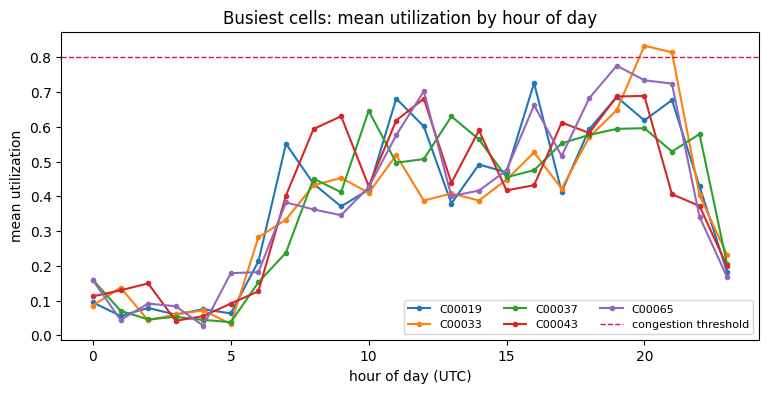

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
top = [r.cell_id for r in spark.sql('SELECT cell_id FROM lake.gold.cell_congestion_ranking ORDER BY congested_hours DESC LIMIT 5').collect()]
pdf = spark.sql(f'''SELECT cell_id, hour(hour_ts) AS hod, avg(utilization) AS u FROM lake.gold.cell_hourly_load
                    WHERE cell_id IN ({','.join(repr(c) for c in top)}) GROUP BY 1, 2 ORDER BY 1, 2''').toPandas()
fig, ax = plt.subplots(figsize=(9, 4))
for cid, g in pdf.groupby('cell_id'):
    ax.plot(g.hod, g.u, marker='o', ms=3, label=cid)
ax.axhline(0.8, ls='--', c='crimson', lw=1, label='congestion threshold')
ax.set_xlabel('hour of day (UTC)'); ax.set_ylabel('mean utilization'); ax.legend(ncol=3, fontsize=8)
ax.set_title('Busiest cells: mean utilization by hour of day'); plt.show()

## 6. Churn features: score deciles

In [7]:
spark.sql('''SELECT decile, count(*) AS subscribers, round(avg(churn_risk_score), 3) AS score,
                    round(avg(usage_trend), 3) AS usage_trend, round(avg(drop_rate), 4) AS drop_rate
             FROM (SELECT *, ntile(10) OVER (ORDER BY churn_risk_score DESC) AS decile FROM lake.gold.churn_features)
             GROUP BY decile ORDER BY decile''').show()

+------+-----------+-----+-----------+---------+
|decile|subscribers|score|usage_trend|drop_rate|
+------+-----------+-----+-----------+---------+
|     1|        200|0.653|      0.167|   0.0701|
|     2|        200|0.498|      0.347|   0.0469|
|     3|        200|0.413|      0.456|   0.0344|
|     4|        200|0.345|      0.512|   0.0294|
|     5|        200|0.293|      0.672|   0.0227|
|     6|        200|0.242|      0.953|   0.0218|
|     7|        200|0.188|      1.042|   0.0157|
|     8|        200|0.124|        1.7|   0.0194|
|     9|        200|0.056|      1.964|   0.0179|
|    10|        200|0.002|      2.483|   5.0E-4|
+------+-----------+-----+-----------+---------+

